# Klassifikation

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import itertools

from sklearn.datasets import load_iris
from sklearn import tree
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from mlxtend.classifier import EnsembleVoteClassifier
from mlxtend.plotting import plot_decision_regions

import torch

## Daten

Der Iris-Datensatz ist ein beliebter Beispieldatensatz. Er enthält vier Merkmale:

* Länge der Kelchblätter (Sepalen, engl. sepal)
* Breite der Kelchblätter
* Länge der Kronblätter (Petalen, engl. petal)
* Breite der Kronblätter

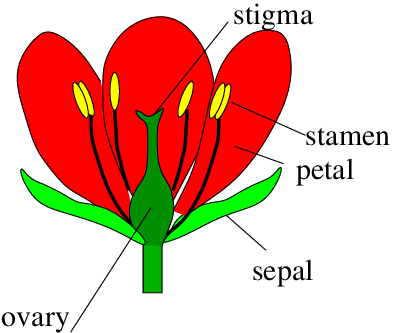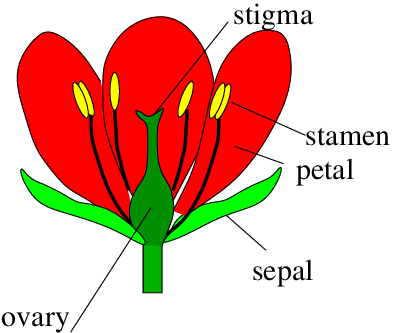

In [2]:
# Lade die Iris-Daten
iris = load_iris()

# Speichere den Input-Datensatz unter X
X = iris.data
# und die Klasse unter y
y = iris.target

### Ein Blick auf die Daten

In [3]:
# Namen der vier Merkmale
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

Die vier Merkmale sind Länge und Breite der Kelch- und Kronblätter, jeweils in Zentimetern.

In [4]:
# Zeige X
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

`X` ist eine Matrix mit 150 Zeilen (Blüten) und 4 Spalten (Merkmale in der Reihenfolge von `iris.feature_names`). Die erste Blüte hat z. B. 5,1 cm lange und 3,5 cm breite Kelchblätter sowie 1,4 cm lange und 0,2 cm breite Kronblätter.

In [5]:
# Wir beschränken uns auf die 1. und 3. Spalte des Datensatzes
X = X[:,[0, 2]]

Damit wir die Ergebnisse in einer zweidimensionalen Grafik darstellen können, verwenden wir nur zwei Merkmale: die Länge der Kelchblätter (Spalte 0) und die Länge der Kronblätter (Spalte 2). Python zählt die Spalten ab 0.

In [6]:
# Namen der drei Klassen (Iris-Arten)
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

Der Datensatz enthält drei Iris-Arten. Sie sind in `y` als Zahlen kodiert: 0 = *setosa*, 1 = *versicolor*, 2 = *virginica*.

In [7]:
# Zeige y
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

`y` enthält für jede der 150 Blüten die Klasse. Die Daten sind nach Klassen sortiert, und jede Art kommt genau 50-mal vor. Der Datensatz ist also *balanciert*.

### Visualisiere die Daten

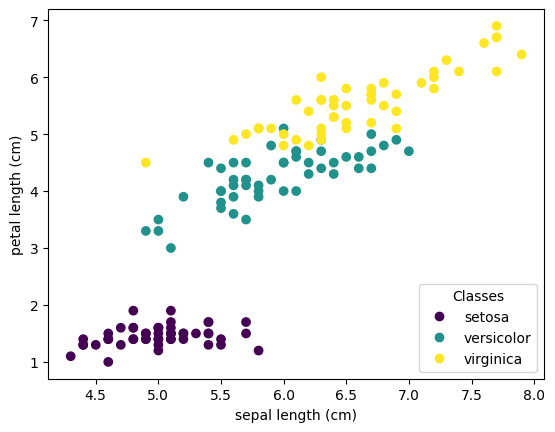

In [8]:
# Generiere eine leere Grafik
fig, ax = plt.subplots()

# Erstelle den Scatterplot
scatter = ax.scatter(x = X[:, 0],
                     y = X[:, 1],
                     c = y)

# Benenne die Achsen
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[2])

# Füge Legende hinzu
ax.legend(scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes")

*Setosa* (unten links) unterscheidet sich klar von den anderen beiden Arten: Ihre Kronblätter sind deutlich kürzer. *Versicolor* und *virginica* überlappen sich dagegen teilweise. Bei diesen beiden Arten werden die Modelle daher Fehler machen.

Die Zeile `<matplotlib.legend.Legend …>` über der Grafik ist nur eine Beschreibung des Legenden-Objekts.

## Decision tree

In [10]:
# Generiere ein "leeres" Modell
dcsntree = tree.DecisionTreeClassifier(random_state=0)

In [11]:
# Zeige Ergebnis an
dcsntree

DecisionTreeClassifier(random_state=0)

Vor dem Training zeigt Jupyter nur die Einstellungen des Modells an. `random_state=0` sorgt dafür, dass das Ergebnis reproduzierbar ist.

In [12]:
# Trainiere das Modell mit den Daten
dcsntree.fit(X, y)

DecisionTreeClassifier(random_state=0)

In [13]:
# Zeige Ergebnis an
dcsntree

DecisionTreeClassifier(random_state=0)

Die Ausgabe sieht genauso aus wie vor dem Training. Das trainierte Modell speichert die gelernten Regeln intern, sie werden in dieser Kurzdarstellung aber nicht angezeigt.

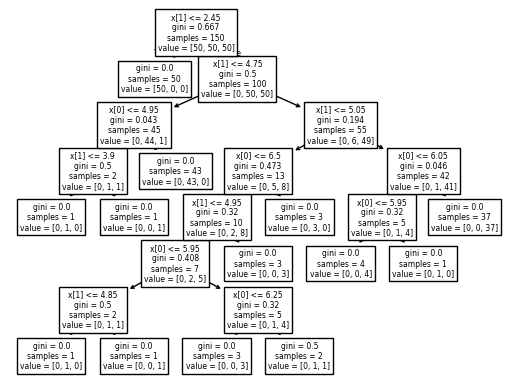

In [15]:
# Zeige den Entscheidungsbaum
tree.plot_tree(dcsntree);

Jeder Kasten ist ein Knoten des Baums. `x[0]` ist die Länge der Kelchblätter, `x[1]` die Länge der Kronblätter. Die erste Zeile enthält die Entscheidungsregel. Ist sie erfüllt, geht es nach links, sonst nach rechts. `samples` ist die Anzahl der Blüten im Knoten, `value` ihre Verteilung auf die drei Klassen und `gini` die Unreinheit (0 = alle Blüten gehören zur selben Klasse).

Schon die erste Regel (Kronblattlänge ≤ 2,45 cm) trennt alle 50 *setosa*-Blüten ab. Die weiteren Ebenen unterscheiden *versicolor* und *virginica*. Weil der Baum ohne Begrenzung wächst, bildet er auch Knoten mit nur einer einzigen Blüte. Das ist ein Hinweis auf *Overfitting*: Der Baum lernt einzelne Ausnahmen auswendig.

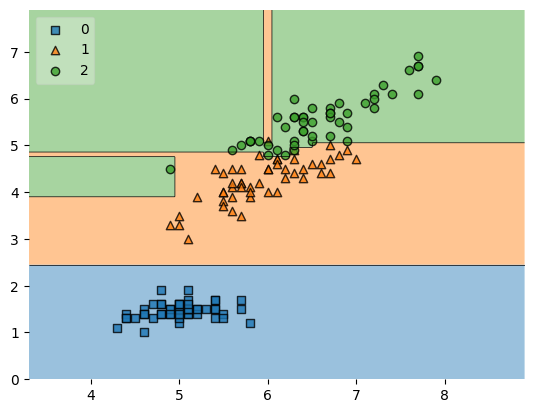

In [16]:
# Zeige die Vorhersagen: Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = dcsntree, legend = 2)

Die farbigen Flächen zeigen, welche Klasse das Modell für jeden Punkt der Ebene vorhersagt. Die Grenzen des Entscheidungsbaums verlaufen immer parallel zu den Achsen, weil jede Regel nur ein Merkmal betrifft. Die kleinen Rechtecke und schmalen Streifen entstehen durch Regeln für einzelne Blüten, ein weiteres Zeichen für Overfitting.

In [17]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, dcsntree.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 50,  0],
       [ 0,  1, 49]])

Die Konfusionsmatrix vergleicht die tatsächlichen Klassen (Zeilen) mit den vorhergesagten Klassen (Spalten). Auf der Diagonale stehen die richtigen Vorhersagen. Der Baum klassifiziert 149 von 150 Blüten richtig, nur eine *virginica* wird als *versicolor* vorhergesagt.

**Achtung:** Wir bewerten das Modell hier mit denselben Daten, mit denen es trainiert wurde. Das überschätzt die Güte des Modells, besonders bei Modellen, die zu Overfitting neigen. In der Praxis teilt man die Daten in Trainings- und Testdaten auf (z. B. mit `train_test_split` aus `sklearn.model_selection`).

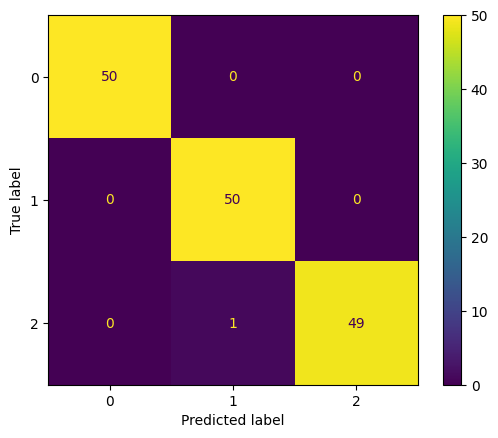

In [18]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

Dieselbe Matrix als Grafik: Je heller das Feld, desto mehr Blüten. Die Zeile `<sklearn.metrics._plot…>` beschreibt nur das Grafik-Objekt.

## Lazy learners (Beispiel KNN)

In [19]:
# Generiere ein "leeres" Modell
knn = KNeighborsClassifier(n_neighbors=1)

# Trainiere das Modell mit den Daten
knn = knn.fit(X, y)

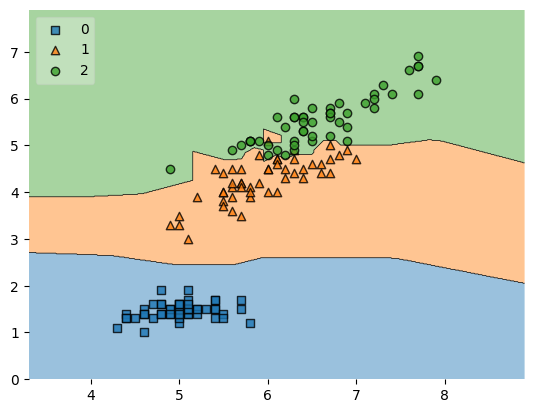

In [20]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = knn, legend = 2)

Mit `n_neighbors=1` übernimmt jeder Punkt der Ebene die Klasse der nächstgelegenen Blüte aus den Trainingsdaten. Die Grenzen sind deshalb unregelmäßig und folgen einzelnen Datenpunkten.

In [21]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, knn.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

Auch KNN klassifiziert 149 von 150 Blüten richtig, hier wird eine *versicolor* als *virginica* vorhergesagt. Dass das Ergebnis auf den Trainingsdaten nicht perfekt ist, liegt an Blüten mit identischen Werten, aber unterschiedlicher Klasse. Auf neuen Daten würde ein KNN mit nur einem Nachbarn vermutlich deutlich schlechter abschneiden.

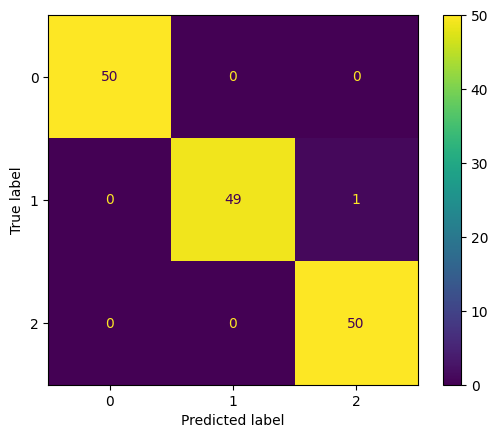

In [22]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Linear classifiers (Beispiel Logistic Regression)

In [23]:
# Generiere ein "leeres" Modell
logreg_res = LogisticRegression(random_state=0)

# Trainiere das Modell mit den Daten
logreg_res = logreg_res.fit(X, y)

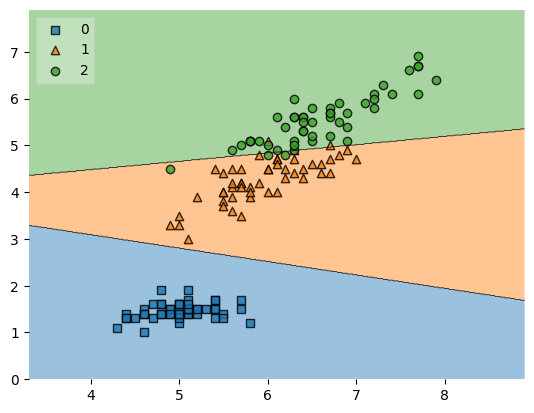

In [24]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = logreg_res, legend = 2)

Die logistische Regression trennt die Klassen mit geraden Linien. Dadurch sind die Grenzen einfach und glatt, aber im Überlappungsbereich von *versicolor* und *virginica* liegen einige Punkte auf der falschen Seite.

In [25]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, logreg_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 47,  3],
       [ 0,  3, 47]])

144 von 150 Blüten werden richtig klassifiziert (96 %). Je drei *versicolor*- und *virginica*-Blüten werden verwechselt. Das einfachere Modell passt sich weniger an einzelne Punkte an und macht auf den Trainingsdaten daher mehr Fehler, ist aber weniger anfällig für Overfitting.

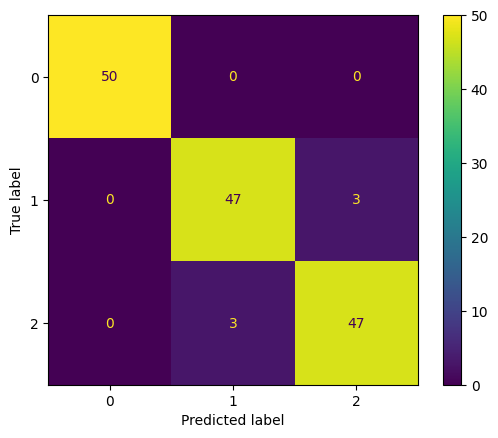

In [26]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Support vector machine (SVM)

In [27]:
# Generiere ein "leeres" Modell
svm_res = SVC(random_state=0, probability=True)

# Trainiere das Modell mit den Daten
svm_res = svm_res.fit(X, y)

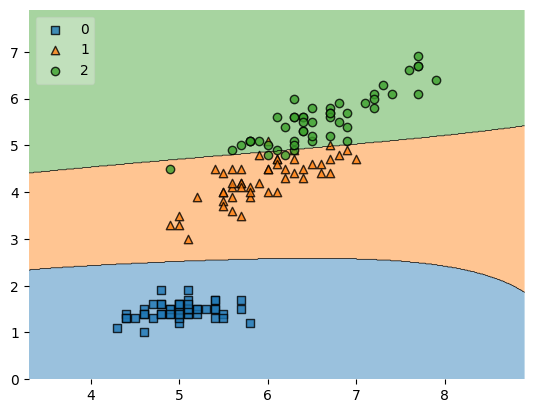

In [28]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = svm_res, legend = 2)

Die SVM (hier mit dem Standard-Kernel RBF) erzeugt geschwungene Grenzen. Sie sind flexibler als bei der logistischen Regression, aber glatter als beim Entscheidungsbaum oder bei KNN.

In [29]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, svm_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  4, 46]])

144 von 150 Blüten werden richtig klassifiziert. Zwei *versicolor*-Blüten werden als *virginica* und vier *virginica*-Blüten als *versicolor* vorhergesagt.

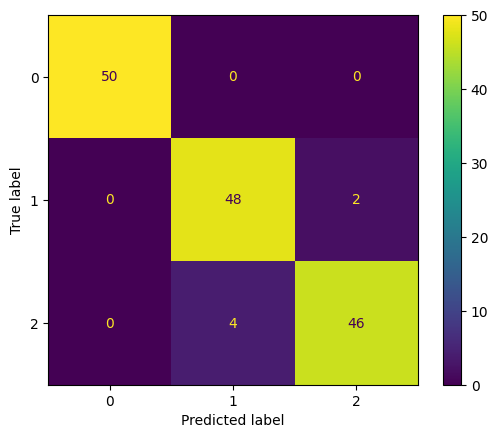

In [30]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Ensembles

Manche Modelle können bestimmte Gruppen besser erkennen als andere. Daher hat es sich bewährt, für bestimmte Gruppen Spezialmodelle zu entwickeln, die dann mithilfe eines Metamodells miteinander verbunden werden. Solche Modelle werden auch als Ensembles bezeichnet.

### Random Forest

Ein Random Forest ist eine Sammlung mehrerer Decision Trees.

In [31]:
# Generiere ein "leeres" Modell
randfor_res = RandomForestClassifier(random_state=0)

# Trainiere das Modell mit den Daten
randfor_res = randfor_res.fit(X, y)

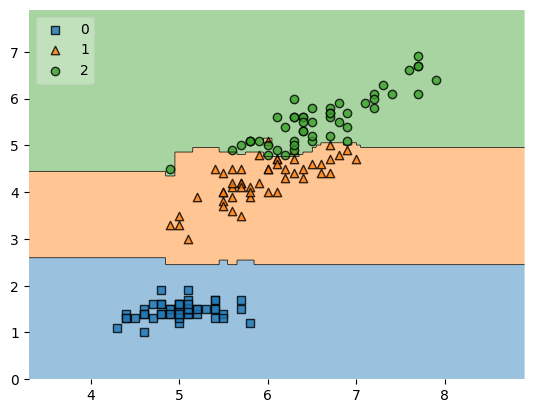

In [32]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = randfor_res, legend = 2)

Der Random Forest kombiniert viele Entscheidungsbäume, die jeweils mit einer zufälligen Stichprobe der Daten trainiert werden. Die Grenzen verlaufen deshalb wie beim einzelnen Baum stufenförmig, sind aber weniger zerklüftet.

In [33]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, randfor_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 49,  1],
       [ 0,  0, 50]])

149 von 150 Blüten werden richtig klassifiziert, eine *versicolor* wird als *virginica* vorhergesagt.

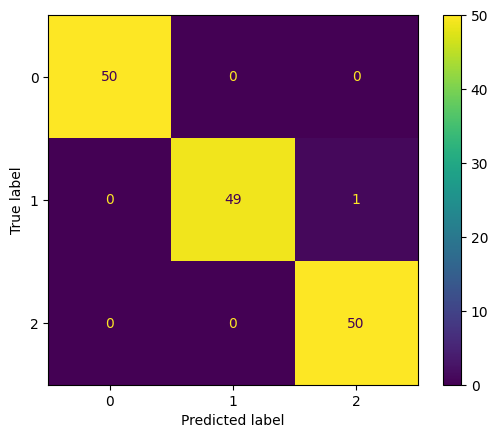

In [34]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

### Ensemble

Es können aber auch unterschiedliche Arten von Submodellen zusammengeführt werden. Im folgenden Beispiel werden die Logistic Regression, das SVM-Modell und der Random Forest kombiniert:

In [35]:
# Generiere die "leeren" Modelle, die im Ensemble verwendet werden sollen
clf1 = LogisticRegression(random_state=0)
clf2 = RandomForestClassifier(random_state=0)
clf3 = SVC(random_state=0, probability=True)

# Füge die Modelle zusammen und gewichte sie
ensemble_res = EnsembleVoteClassifier(clfs=[clf1, clf2, clf3],
                              weights=[2, 1, 1],
                              voting='soft')

# Trainiere das Ensemble mit den Daten
ensemble_res = ensemble_res.fit(X, y)

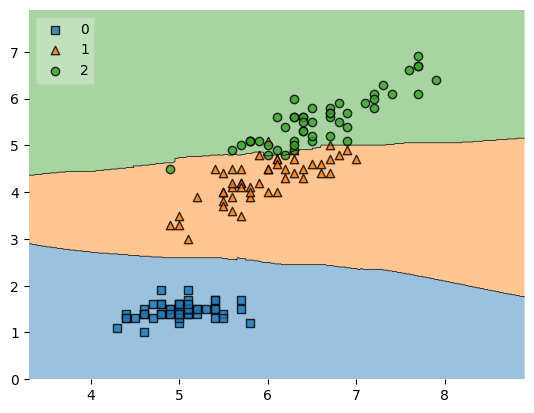

In [36]:
# Zeichne die Entscheidungsregionen des Modells mit den Datenpunkten
fig = plt.figure()
ax = plt.subplot()
fig = plot_decision_regions(X=X, y=y, clf = ensemble_res, legend = 2)

Die Grenzen des Ensembles sind eine Mischung aus den Grenzen der drei Modelle. Da die logistische Regression doppelt gewichtet ist, verlaufen sie nahezu geradlinig, haben aber kleine Stufen vom Random Forest.

In [37]:
# Vergleiche tatsächliche Klassen (Zeilen) mit vorhergesagten Klassen (Spalten)
confusion_matrix = metrics.confusion_matrix(y, ensemble_res.predict(X))
confusion_matrix

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0,  1, 49]])

147 von 150 Blüten werden richtig klassifiziert. Das Ensemble ist damit besser als die logistische Regression und die SVM allein, aber etwas schlechter als der Random Forest. Auf den Trainingsdaten gewinnt meist das flexibelste Modell. Ob das Ensemble auf neuen Daten besser ist, ließe sich nur mit Testdaten beurteilen.

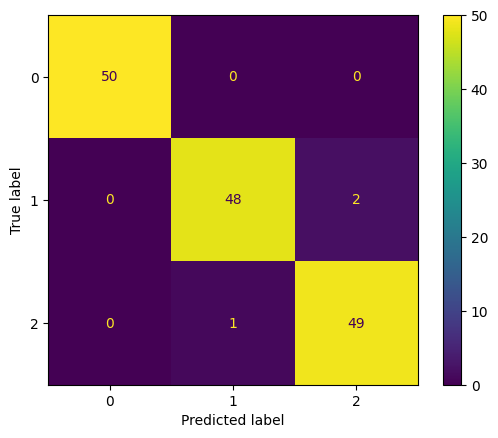

In [38]:
# Stelle die Konfusionsmatrix grafisch dar
plot_confusion_matrix = metrics.ConfusionMatrixDisplay(confusion_matrix)
plot_confusion_matrix.plot()

## Neuronale Netze

In [40]:
# Normalisiere die Input-Daten
X = normalize(X, axis=0, norm='max')

# Ändere das Datenformat
X = X.astype(np.float32) 
y = y.astype(np.float32)

In [42]:
# Reduziere das Modell auf zwei Klassen
pos = y != 1
X = X[pos]
y = y[pos]

# Kodiere virginica neu: aus Label 2 wird 1, damit die Klassen 0 und 1 sind
y[y == 2] = 1

Ab hier verwenden wir nur noch *setosa* und *virginica*. Da *virginica* ursprünglich das Label 2 hat, kodieren wir es in 1 um. So enthält `y` die Werte 0 (*setosa*) und 1 (*virginica*), und das Modell soll Werte nahe 0 bzw. 1 vorhersagen.

In [44]:
# Spezifiziere die Anzahl der Input- und Output-Knoten
input_dim = 2 # Anzahl der Input-Knoten -> x- u. y-Achse
output_dim = 1 # Anzahl der Output-Knoten -> Label: 0, 1

# Wandle die NumPy-Arrays in PyTorch-Tensoren um
X_t = torch.from_numpy(X)
y_t = torch.from_numpy(y).reshape(-1, 1) # Spaltenvektor, damit die Form zu den Vorhersagen passt

# Setze einen Zufalls-Seed, damit die Startwerte reproduzierbar sind
torch.manual_seed(0)

# Definiere die Parameter des Modells
# requires_grad=True: PyTorch merkt sich alle Rechenschritte, um später Gradienten zu berechnen
W = torch.rand(input_dim, output_dim, requires_grad = True)
b = torch.zeros(output_dim, requires_grad = True)

Das „Netz“ besteht hier aus einem einzigen Neuron ohne Aktivierungsfunktion: Die Vorhersage ist eine gewichtete Summe der beiden Merkmale plus eine Konstante. `W` enthält die zwei Gewichte (zufällige Startwerte zwischen 0 und 1), `b` die Konstante (Startwert 0). Mit `torch.manual_seed(0)` erhalten wir bei jedem Durchlauf dieselben Startwerte.

PyTorch rechnet mit *Tensoren* statt mit NumPy-Arrays. `torch.from_numpy` wandelt die Daten um. `y_t` bringen wir mit `reshape(-1, 1)` in dieselbe Form wie die Vorhersagen (100 Zeilen, 1 Spalte), damit beim Vergleich jede Vorhersage mit ihrem eigenen Label verglichen wird.

In [45]:
# Definiere das Modell
def model(inputs):
    return inputs @ W + b # a*W + b (@ ist die Matrixmultiplikation)

In [46]:
# Definiere die Loss-Funktion
def square_loss(targets, predictions):
    per_sample_losses = (targets - predictions) ** 2
    return per_sample_losses.mean()

In [47]:
# Definiere den Lern-Algorithmus
learning_rate = 0.1

def training_step(inputs, targets):
    predictions = model(inputs) # Mache Vorschlag (Predictions)
    loss = square_loss(targets, predictions) # Berechne Loss, d.h. vergleiche Predictions mit tatsächlichen Werten
    loss.backward() # Berechne Gradienten, sie landen in W.grad und b.grad
    with torch.no_grad(): # Die Updates selbst sollen nicht in die Gradienten eingehen
        W.sub_(W.grad * learning_rate) # Update W
        b.sub_(b.grad * learning_rate) # Update b
        W.grad.zero_() # Setze die Gradienten zurück, sonst würden sie aufsummiert
        b.grad.zero_()
    return loss.item()

In [48]:
# Training
for step in range(40):
    loss = training_step(X_t, y_t)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 0.1196
Loss at step 1: 0.0874
Loss at step 2: 0.0735
Loss at step 3: 0.0670
Loss at step 4: 0.0635
Loss at step 5: 0.0613
Loss at step 6: 0.0596
Loss at step 7: 0.0581
Loss at step 8: 0.0568
Loss at step 9: 0.0555
Loss at step 10: 0.0543
Loss at step 11: 0.0531
Loss at step 12: 0.0519
Loss at step 13: 0.0508
Loss at step 14: 0.0497
Loss at step 15: 0.0486
Loss at step 16: 0.0476
Loss at step 17: 0.0466
Loss at step 18: 0.0456
Loss at step 19: 0.0446
Loss at step 20: 0.0437
Loss at step 21: 0.0428
Loss at step 22: 0.0419
Loss at step 23: 0.0411
Loss at step 24: 0.0403
Loss at step 25: 0.0395
Loss at step 26: 0.0387
Loss at step 27: 0.0379
Loss at step 28: 0.0372
Loss at step 29: 0.0365
Loss at step 30: 0.0358
Loss at step 31: 0.0351
Loss at step 32: 0.0345
Loss at step 33: 0.0338
Loss at step 34: 0.0332
Loss at step 35: 0.0326
Loss at step 36: 0.0320
Loss at step 37: 0.0314
Loss at step 38: 0.0309
Loss at step 39: 0.0304


Der Loss (die mittlere quadrierte Abweichung zwischen Vorhersage und Label) fällt in den ersten Schritten stark, von 0,12 auf rund 0,06 nach fünf Schritten, und sinkt danach langsamer bis auf 0,03. Zum Vergleich: Ein Modell, das für jede Blüte einfach 0,5 vorhersagt, hätte einen Loss von 0,25. Mit mehr Trainingsschritten würde der Loss weiter sinken.

In jedem Schritt passiert dasselbe: Vorhersage berechnen, Loss berechnen, mit `loss.backward()` die Gradienten bestimmen und die Parameter ein kleines Stück (`learning_rate`) gegen die Richtung des Gradienten verschieben.

In [49]:
# Zeige die Vorhersagen des Modells an
with torch.no_grad(): # Für Vorhersagen brauchen wir keine Gradienten
    predictions = model(X_t)
predictions

tensor([[0.1626],
        [0.1526],
        [0.1275],
        [0.1527],
        [0.1576],
        [0.2230],
        [0.1376],
        [0.1727],
        [0.1276],
        [0.1677],
        [0.1928],
        [0.1779],
        [0.1476],
        [0.0772],
        [0.1674],
        [0.2078],
        [0.1625],
        [0.1626],
        [0.2381],
        [0.1777],
        [0.2230],
        [0.1777],
        [0.0771],
        [0.2080],
        [0.2232],
        [0.1879],
        [0.1879],
        [0.1828],
        [0.1676],
        [0.1728],
        [0.1779],
        [0.1928],
        [0.1828],
        [0.1827],
        [0.1677],
        [0.1274],
        [0.1675],
        [0.1526],
        [0.1124],
        [0.1777],
        [0.1425],
        [0.1174],
        [0.1124],
        [0.1879],
        [0.2383],
        [0.1476],
        [0.1929],
        [0.1376],
        [0.1878],
        [0.1576],
        [0.9187],
        [0.7575],
        [0.9436],
        [0.8582],
        [0.8984],
        [1

Für jede der 100 Blüten gibt es eine Vorhersage. Für die *setosa*-Blüten (die ersten 50) liegen die Werte zwischen etwa 0,08 und 0,24, für die *virginica*-Blüten zwischen etwa 0,62 und 1,13. Die Vorhersagen sind also schon in der Nähe der Labels 0 und 1, und die beiden Arten sind klar getrennt: Jede *virginica* hat einen höheren Wert als jede *setosa*.

Da das Modell keine Aktivierungsfunktion hat, sind die Vorhersagen nicht auf den Bereich zwischen 0 und 1 beschränkt. Deshalb können Werte über 1 vorkommen.

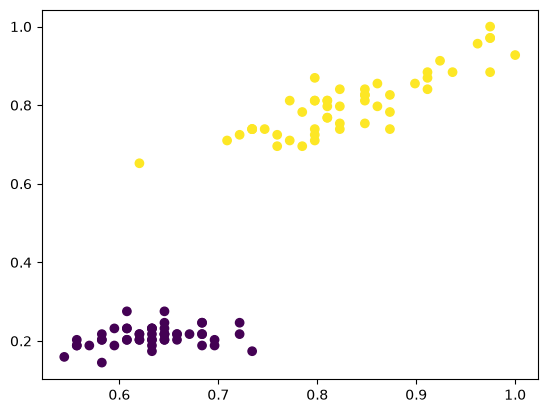

In [50]:
# Färbe die Punkte danach, ob die Vorhersage größer als 0,5 ist
plt.scatter(X[:, 0], X[:, 1], c = (predictions[:, 0] > 0.5).numpy())
plt.show()

Mit dem Schwellenwert 0,5 (der Mitte zwischen den Labels 0 und 1) werden alle 100 Blüten richtig getrennt: Die *setosa*-Blüten (unten links) liegen darunter, die *virginica*-Blüten (oben rechts) darüber.

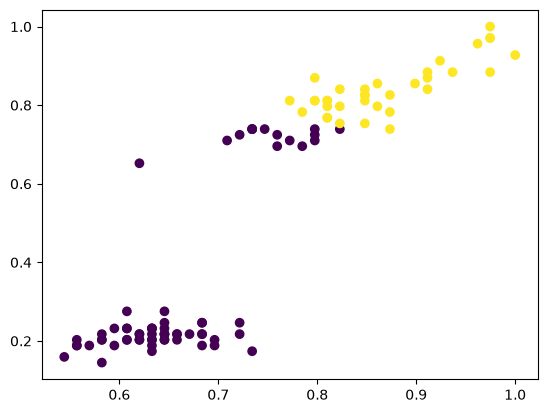

In [52]:
# Schwellenwert 0,8
plt.scatter(X[:, 0], X[:, 1], c = (predictions[:, 0] > 0.8).numpy())
plt.show()

Bei 0,8 liegen nur noch 35 der 50 *virginica*-Blüten über dem Schwellenwert. Die übrigen 15, vor allem die mit kleineren Blättern, werden jetzt fälschlich der Klasse 0 zugeordnet.

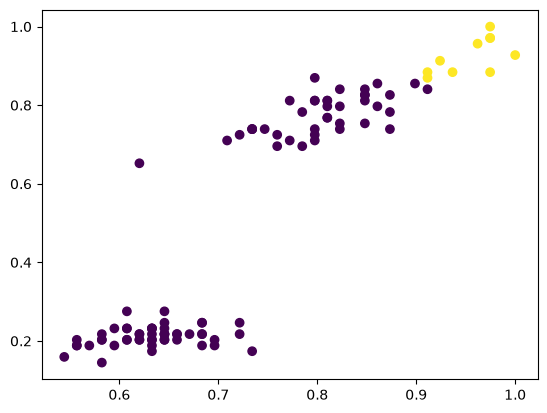

In [54]:
# Schwellenwert 0,95
plt.scatter(X[:, 0], X[:, 1], c = (predictions[:, 0] > 0.95).numpy())
plt.show()

Bei 0,95 sind es nur noch 10 *virginica*-Blüten. Ein zu hoher Schwellenwert ordnet also viele Blüten der Klasse 0 zu. Welcher Schwellenwert sinnvoll ist, hängt davon ab, wie gut das Modell trainiert ist und welche Fehler schwerer wiegen. Ohne besonderen Grund ist die Mitte zwischen den Labels (hier 0,5) die naheliegende Wahl.

## Quellen

* https://scikit-learn.org/1.5/auto_examples/datasets/plot_iris_dataset.html
* https://scikit-learn.org/1.5/modules/tree.html
* https://rasbt.github.io/mlxtend/
* https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html